In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
from argparse import ArgumentParser
from tqdm import trange

sys.path.append(os.getcwd()+"/..")

# Placeholder for your custom functions
from simulation.utils import (
    generate_unit_cell_anisotropy, 
    lattice_parameters_reciprocal,
    reciprocal_lattice_vectors, 
    random_rotate_vectors,
    generate_reciprocal_lattice,
    fibonacci_orientations,
    orientations_to_indices,
    align_reciprocal_lattice,
    simulate_diffraction_experiment,
    project_reflections_2D,
    remove_random_pairs,
    add_random_pairs,
    add_noise,
    shift_points,
    save_parameters,
    is_linear_combination,
    find_linear_independent
)


Generated unit cell parameters:
a = 9.146 Å
b = 6.610 Å
c = 9.819 Å
alpha = 92.34°
beta = 101.18°
gamma = 112.91°
Reciprocal lattice parameters:
astar = 0.200
bstar = 0.167
cstar = 0.143
alphastar = 90.000°
betastar = 90.000°
gammastar = 90.000°
True


In [2]:
target_volume = 500
volume_error = 100
a_range = [3.5, 15]
b_range = [4, 30]
c_range = [5, 45]
alpha_range = [90, 120]
beta_range = [90, 120]
gamma_range = [90, 120]
anisotropy = 1.5
resolution = 0.85
wavelength = 0.0407
excitation_error = 0.015
detector_distance = 0
edge = 1.5
fraction_limit_missing = 0.03
fraction_limit_additional = 0.05
noise_level = 0.0012
max_shift = 0.01
N = 1000
zonal_sample_threshold = 0.9
zonal_segmentation_threshold = 0.4
output_folder = "output"

# Generate unit cell parameters
a, b, c, alpha, beta, gamma = generate_unit_cell_anisotropy(
    target_volume, a_range, b_range, c_range, alpha_range, beta_range, gamma_range, volume_error, anisotropy
)

# Round the parameters
a = round(a, 3)
b = round(b, 3)
c = round(c, 3)
alpha = round(alpha, 2)
beta = round(beta, 2)
gamma = round(gamma, 2)

# Display results
print(f"Generated unit cell parameters:")
print(f"a = {a:.3f} Å")
print(f"b = {b:.3f} Å")
print(f"c = {c:.3f} Å")
print(f"alpha = {alpha:.2f}°")
print(f"beta = {beta:.2f}°")
print(f"gamma = {gamma:.2f}°")


# Compute reciprocal lattice parameters
astar, bstar, cstar, alphastar, betastar, gammastar = lattice_parameters_reciprocal(a, b, c, alpha, beta, gamma)
v1, v2, v3 = reciprocal_lattice_vectors(astar, bstar, cstar, alphastar, betastar, gammastar)

astar_rot, bstar_rot, cstar_rot = random_rotate_vectors(v1, v2, v3)

# Generate reciprocal lattice reflections
hkl_list, reflections = generate_reciprocal_lattice(v1, v2, v3, resolution)

orientations = fibonacci_orientations(N)
indices = orientations_to_indices(orientations, astar_rot, bstar_rot, cstar_rot)
# Parameters
R = 1 / wavelength

# Compute Ewald sphere
theta, phi = np.meshgrid(np.linspace(0, np.pi, 50), np.linspace(0, 2 * np.pi, 100))
X = R * np.sin(theta) * np.cos(phi)
Y = R * np.sin(theta) * np.sin(phi)
Z = R * np.cos(theta)

# Shift the sphere to the Ewald center
X = X + 0
Y = Y + 0
Z = Z + R


Generated unit cell parameters:
a = 10.013 Å
b = 7.260 Å
c = 7.084 Å
alpha = 101.67°
beta = 107.06°
gamma = 91.58°


In [5]:
i = 0
rotated_reflections = align_reciprocal_lattice(reflections, orientations[i, :])
ewald_sphere, diffraction_spots, hkl_included = simulate_diffraction_experiment(hkl_list, rotated_reflections, wavelength, excitation_error)

In [6]:
camera_direction = orientations[i, :]
camera_position = camera_direction * 1 / wavelength * 0.1
center = np.array([0.0, 0.0, 0.0])
dir_vec = center - camera_position
dir_unit = dir_vec / np.linalg.norm(dir_vec)

z_axis = np.array([0.0, 0.0, 1.0])
v = np.cross(z_axis, dir_unit)
s = np.linalg.norm(v)
c = np.dot(z_axis, dir_unit)
if s < 1e-8:
    rot_mat = np.eye(3) if c > 0 else np.diag([1.0, -1.0, -1.0])
else:
    K = np.array([[0.0, -v[2], v[1]], [v[2], 0.0, -v[0]], [-v[1], v[0], 0.0]])
    rot_mat = np.eye(3) + K + K @ K * ((1.0 - c) / (s**2))

camera_extrinsics = np.eye(4)
camera_extrinsics[:3, :3] = rot_mat
camera_extrinsics[:3, 3] = camera_position

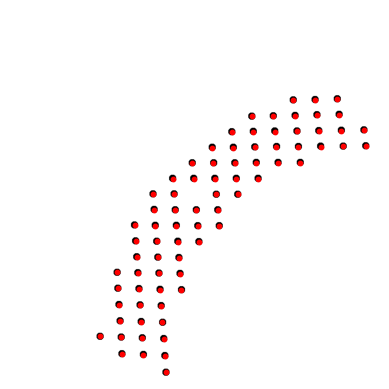

In [ ]:

canvas_size = 1000
focal_length = canvas_size * 1
K_intrinsic = np.array([[focal_length, 0, canvas_size // 2], [0, focal_length, canvas_size // 2], [0, 0, 1]])
T_extrinsics = np.linalg.inv(camera_extrinsics)

world_pts_homogeneous = np.hstack([diffraction_spots, np.ones((diffraction_spots.shape[0], 1))])
projected_pts_homogeneous = ((K_intrinsic @ T_extrinsics[:3, :]) @ world_pts_homogeneous.T).T
projected_x = projected_pts_homogeneous[:, 0] / projected_pts_homogeneous[:, 2]
projected_y = projected_pts_homogeneous[:, 1] / projected_pts_homogeneous[:, 2]
depth = projected_pts_homogeneous[:, 2]


canvas = np.ones((canvas_size, canvas_size), dtype=np.uint8) * 255
depth_map = np.full((canvas_size, canvas_size), np.inf)

meshgrid_x, meshgrid_y = np.meshgrid(np.arange(canvas_size), np.arange(canvas_size))
meshgrid_points = np.stack([meshgrid_x, meshgrid_y], axis=-1).reshape(-1, 2)
for x, y, d in zip(projected_x, projected_y, depth):
    if 0 <= x < canvas.shape[1] and 0 <= y < canvas.shape[0]:
        circle_radius = 10
        circle_center = np.array([x, y], dtype=np.int32)
        canvas[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = 0
        depth_map[(meshgrid_x - circle_center[0]) ** 2 + (meshgrid_y - circle_center[1]) ** 2 < circle_radius ** 2] = d

center = np.array([0, 0, 0])

plt.imshow(canvas, cmap='gray')
plt.axis('off')
plt.scatter(projected_x, projected_y, color='red', s=10)
